# Recipe Recommendation System

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics.pairwise import cosine_similarity
from tqdm.notebook import tqdm
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)


## Data Loading

- **fe_user_recipe_matrix**: User-recipe interactions (1=liked, 0=not liked)
- **user_recipe_matrix_train_only**: Same as above, with test cells marked as 2
- **fe_recipe_attribute_matrix_file84**: 84 recipe features (81 ingredients + 3 cooking methods)


In [2]:
user_recipe_full = pd.read_csv('fe_user_recipe_matrix.csv')
user_recipe_train = pd.read_csv('user_recipe_matrix_train_only.csv')
recipe_attr = pd.read_csv('fe_recipe_attribute_matrix_file84.csv')

if 'user_id' in user_recipe_full.columns:
    user_recipe_full = user_recipe_full.drop('user_id', axis=1)

print(f"Users: {user_recipe_full.shape[0]}")
print(f"Recipes: {user_recipe_full.shape[1]}")
print(f"Recipe attributes: {recipe_attr.shape[1] - 3}")


Users: 1000
Recipes: 1000
Recipe attributes: 84


In [3]:
missing = (user_recipe_train.isna().values).sum()
print(f"Missing ratings: {missing}")

# change test cells to NaN values to predict
test_count = (user_recipe_train.values == 2).sum()
print(f"Test cells (to predict): {test_count}")
print(f"Test fraction: {test_count / user_recipe_train.size:.1%}")

user_recipe_train.replace(2, np.nan, inplace=True)

Missing ratings: 0
Test cells (to predict): 100000
Test fraction: 10.0%


In [4]:
user_recipe_train.head()

,slow-cooker-pot-roast:295,chicken-cordon-bleu-ish-grilled-sandwich:920,stuffed-eggplant-with-shrimp-and-basil:609,corn-dog-casserole-2:799,sweet-and-sour-chicken-i:103,easy-salsa-meatloaf:434,taco-in-a-bag:924,grilled-lemon-herb-pork-chops:240,chicken-and-broccoli-pasta:995,mashed-potato-quesadilla:895,...,flank-steak-pinwheels:705,chili-rellenos-casserole:176,kabob-marinade:625,herb-rubbed-sirloin-tip-roast:129,tropical-grilled-pork-chops:339,tantalizing-turkey-and-blue-cheese-meatballs:359,easiest-filet-marsala:933,asparagus-lasagna:724,slow-cooker-bbq-chicken:349,baked-chicken-2:470
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,1.0,0.0,NaN,0.0,0.0,...,NaN,0.0,NaN,0.0,0.0,0.0,0.0,1.0,NaN,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,NaN,0.0,1.0,0.0,0.0,0.0,NaN
4,0.0,0.0,0.0,0.0,0.0,NaN,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


---
# 1A: k-Nearest Neighbors Approach

Implementation of a simple k-NN using only the user-recipe matrix (no recipe attributes).

## User-Based k-NN

**Method:**
1. **Similarity function**: Pearson correlation between users
2. **Neighborhood**: k most similar users who have rated item i
3. **Prediction**: Weighted average deviation from user mean:

$$\hat{r}(u,i) = \bar{r}_u + \frac{\sum_{v \in N_k(u)} sim(u,v) \cdot (r_{v,i} - \bar{r}_v)}{\sum_{v \in N_k(u)} sim(u,v)}$$


In [5]:
train_matrix = user_recipe_train.values
full_matrix = user_recipe_full.values

# user similarity (Pearson correlation)
user_sim = pd.DataFrame(train_matrix).T.corr().values
np.fill_diagonal(user_sim, 0)  # exclude self-similarity


In [6]:
def knn_user_based(train, sim, k):
    """User-based k-NN prediction."""
    n_users, n_items = train.shape
    means = np.nanmean(train, axis=1)
    ratings = np.zeros_like(train)
    
    for u in tqdm(range(n_users), desc=f'User-kNN k={k}'):
        test_items = np.argwhere(np.isnan(train[u])).ravel()
        for i in test_items:
            # Users who rated item i
            rated = np.argwhere(~np.isnan(train[:, i])).ravel()
            # k nearest among those who rated
            neighbors = rated[np.argsort(sim[u, rated])[-k:]]
            
            sim_sum = np.sum(sim[u, neighbors])
            if sim_sum > 0:
                dev = train[neighbors, i] - means[neighbors]
                ratings[u, i] = means[u] + np.dot(sim[u, neighbors], dev) / sim_sum
            else:
                ratings[u, i] = means[u]
    return ratings


## Item-Based k-NN

**Method:**
1. **Similarity function**: Cosine similarity between item vectors
2. **Neighborhood**: k most similar items rated by user u
3. **Prediction**: Weighted average deviation from item mean:

$$\hat{r}(u,i) = \bar{r}_i + \frac{\sum_{j \in N_k(i)} sim(i,j) \cdot (r_{u,j} - \bar{r}_j)}{\sum_{j \in N_k(i)} sim(i,j)}$$


In [7]:
# item similarity (cosine) - using mean-filled matrix
train_filled = np.where(np.isnan(train_matrix), 
                        np.nanmean(train_matrix), train_matrix)
item_sim = cosine_similarity(train_filled.T)
np.fill_diagonal(item_sim, 0)


In [8]:
def knn_item_based(train, sim, k):
    """Item-based k-NN prediction."""
    n_users, n_items = train.shape
    means = np.nanmean(train, axis=0)  # item means
    ratings = np.zeros_like(train)
    
    for u in tqdm(range(n_users), desc=f'Item-kNN k={k}'):
        test_items = np.argwhere(np.isnan(train[u])).ravel()
        rated_items = np.argwhere(~np.isnan(train[u])).ravel()
        
        for i in test_items:
            # k nearest items among rated
            neighbors = rated_items[np.argsort(sim[i, rated_items])[-k:]]
            
            sim_sum = np.sum(sim[i, neighbors])
            if sim_sum > 0:
                dev = train[u, neighbors] - means[neighbors]
                ratings[u, i] = means[i] + \
                    np.dot(sim[i, neighbors], dev) / sim_sum
            else:
                ratings[u, i] = means[i]
    return ratings


In [9]:
# Run k-NN for k=5, 10
ks = [5, 10]

user_knn_ratings = {k: knn_user_based(train_matrix, user_sim, k) for k in ks}
item_knn_ratings = {k: knn_item_based(train_matrix, item_sim, k) for k in ks}


User-kNN k=5:   0%|          | 0/1000 [00:00<?, ?it/s]

User-kNN k=10:   0%|          | 0/1000 [00:00<?, ?it/s]

Item-kNN k=5:   0%|          | 0/1000 [00:00<?, ?it/s]

Item-kNN k=10:   0%|          | 0/1000 [00:00<?, ?it/s]

---
# 1B: Logit-Based Approach

Using recipe attributes to predict preferences via logistic regression per user.

## Simple Logit

I fit a separate logistic regression for each user using 84 ingredient/cooking features.
Each user has ~900 training samples. In the beginning, let's examine coefficient distributions without regularization.


In [10]:
# Prepare data with recipe attributes
user_recipe_train_df = pd.read_csv('user_recipe_matrix_train_only.csv')
user_recipe_train_df.replace(2, np.nan, inplace=True)
user_recipe_train_df['user_id'] = user_recipe_train_df.index

df_train = pd.melt(user_recipe_train_df, id_vars='user_id',
                   var_name='recipe_name', value_name='y')
df_train['recipe_name'] = df_train['recipe_name'].str.split(':').str[0]

# Merge with attributes
df_train = df_train.merge(recipe_attr, on='recipe_name')

# Define features (exclude metadata columns)
feature_cols = [c for c in recipe_attr.columns 
                if c not in ['recipe_name', 'popularity_order', 'random_order']]
print(f"Features: {len(feature_cols)}")

train_data = df_train[df_train['y'].notna()]
test_data = df_train[df_train['y'].isna()]


Features: 84


In [11]:
def run_logit(penalty, C, solver):
    """Fit logit per user, return coefficients and predictions."""
    n_users = df_train['user_id'].nunique()
    n_recipes = recipe_attr.shape[0]
    
    probs = np.zeros((n_users, n_recipes))
    all_coeffs = []
    
    model = LogisticRegression(penalty=penalty, C=C, solver=solver,
                               max_iter=1000)
    
    for uid in tqdm(range(n_users), desc=f'Logit {penalty}'):
        X_tr = train_data[train_data['user_id'] == uid][feature_cols]
        y_tr = train_data[train_data['user_id'] == uid]['y']
        
        model.fit(X_tr, y_tr)
        all_coeffs.append(model.coef_[0])
        
        # Predict on all recipes for this user
        user_df = df_train[df_train['user_id'] == uid][feature_cols]
        probs[uid] = model.predict_proba(user_df)[:, 1]
    
    return np.array(all_coeffs), probs


In [12]:
# Simple logit without regularization
coeffs_noreg, probs_noreg = run_logit(penalty=None, C=1.0, solver='lbfgs')


Logit None:   0%|          | 0/1000 [00:00<?, ?it/s]

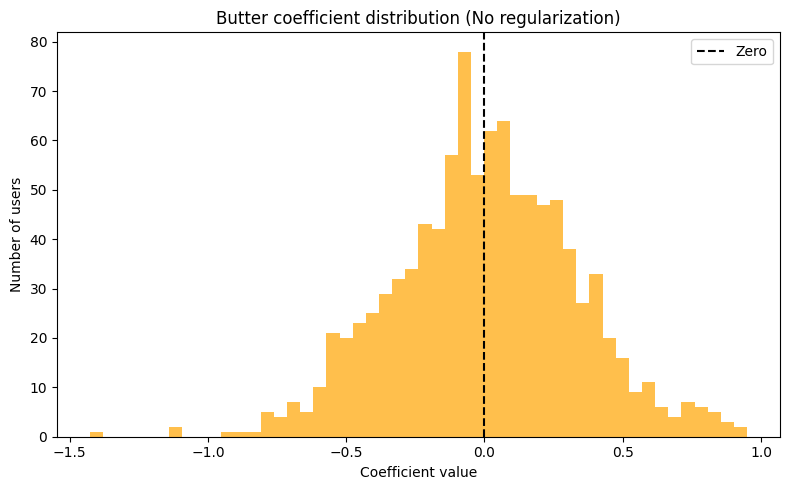

Coefficient range: [-1.4, 0.9]


In [13]:
# Plot coefficient distribution for 'butter'
fig, ax = plt.subplots(figsize=(8, 5))
butter_idx = feature_cols.index('butter')
ax.hist(coeffs_noreg[:, butter_idx], bins=50, color='orange', alpha=0.7)
ax.axvline(0, color='black', linestyle='--', label='Zero')
ax.set_xlabel('Coefficient value')
ax.set_ylabel('Number of users')
ax.set_title('Butter coefficient distribution (No regularization)')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Coefficient range: [{coeffs_noreg[:, butter_idx].min():.1f}, "
      f"{coeffs_noreg[:, butter_idx].max():.1f}]")


## Observation from Plot Above

The 'butter' coefficient ranges from -1.4 to 0.9 across users. The distribution shows natural variation in how different users weight this ingredient.

## Regularized Logit

We apply L2 regularization to see if it changes the coefficient distribution:

$$L_{reg} = L_{logit} + \lambda ||w||_2^2$$

Using C=1.0 (λ=1/C=1) to shrink coefficients toward zero.


In [14]:
# L2 regularized logit
coeffs_l2, probs_l2 = run_logit(penalty='l2', C=1.0, solver='lbfgs')


Logit l2:   0%|          | 0/1000 [00:00<?, ?it/s]

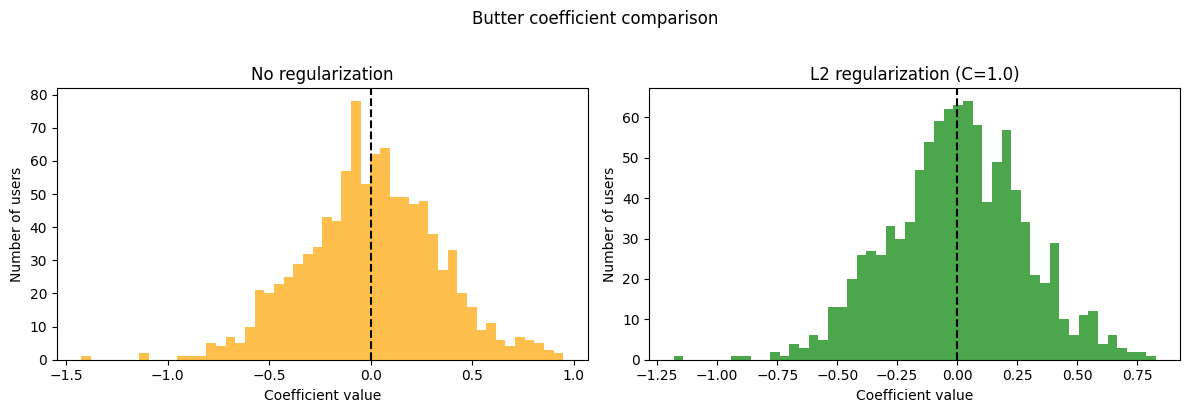

No reg range: [-1.4, 0.9]
L2 reg range: [-1.18, 0.83]
Regularization shrinks coefficients to reasonable range.


In [15]:
# Compare coefficient distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(coeffs_noreg[:, butter_idx], bins=50, color='orange', alpha=0.7)
axes[0].axvline(0, color='black', linestyle='--')
axes[0].set_xlabel('Coefficient value')
axes[0].set_ylabel('Number of users')
axes[0].set_title('No regularization')

axes[1].hist(coeffs_l2[:, butter_idx], bins=50, color='green', alpha=0.7)
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_xlabel('Coefficient value')
axes[1].set_ylabel('Number of users')
axes[1].set_title('L2 regularization (C=1.0)')

plt.suptitle('Butter coefficient comparison', y=1.02)
plt.tight_layout()
plt.show()

print(f"No reg range: [{coeffs_noreg[:, butter_idx].min():.1f}, "
      f"{coeffs_noreg[:, butter_idx].max():.1f}]")
print(f"L2 reg range: [{coeffs_l2[:, butter_idx].min():.2f}, "
      f"{coeffs_l2[:, butter_idx].max():.2f}]")
print("Regularization shrinks coefficients to reasonable range.")


---
# Model Evaluation

Metrics computed on test cells only:
- **MAE**: Mean Absolute Error
- **RMSE**: Root Mean Square Error  
- **Precision@N**: Fraction of top-N recommendations that are liked
- **Recall@N**: Fraction of liked items in top-N
- **F1@N**: Harmonic mean of Precision and Recall


In [16]:
def get_test_indices():
    """Return (user, item) indices of test cells."""
    train_orig = pd.read_csv('user_recipe_matrix_train_only.csv')
    return np.argwhere(train_orig.values == 2)

test_idx = get_test_indices()
print(f"Test cells: {len(test_idx)}")


Test cells: 100000


In [17]:
def evaluate_model(ratings, top_n):
    """Compute metrics for given ratings matrix."""
    # MAE and RMSE on test cells
    errors = []
    for u, i in test_idx:
        pred = ratings[u, i]
        true = full_matrix[u, i]
        errors.append(pred - true)
    
    errors = np.array(errors)
    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors**2))
    
    # Top-N metrics per user
    TP, FP, FN = 0, 0, 0
    
    for u in range(ratings.shape[0]):
        user_test = test_idx[test_idx[:, 0] == u, 1]
        if len(user_test) == 0:
            continue
        
        # Top-N from test items only
        test_ratings = [(i, ratings[u, i]) for i in user_test]
        test_ratings.sort(key=lambda x: x[1], reverse=True)
        top_items = [i for i, _ in test_ratings[:top_n]]
        
        for i in user_test:
            actual = full_matrix[u, i]
            if i in top_items:
                if actual == 1:
                    TP += 1
                else:
                    FP += 1
            else:
                if actual == 1:
                    FN += 1
    
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) \
        if (precision + recall) > 0 else 0
    
    return {'MAE': mae, 'RMSE': rmse, 
            'Precision': precision, 'Recall': recall, 'F1': f1}


In [18]:
# Evaluate all models
Ns = [3, 5, 7, 10]
results = []

for k in ks:
    for n in Ns:
        m = evaluate_model(user_knn_ratings[k], n)
        results.append({'Model': f'User-kNN (k={k})', 'N': n, **m})
        
        m = evaluate_model(item_knn_ratings[k], n)
        results.append({'Model': f'Item-kNN (k={k})', 'N': n, **m})

for n in Ns:
    m = evaluate_model(probs_noreg, n)
    results.append({'Model': 'Logit (no reg)', 'N': n, **m})
    
    m = evaluate_model(probs_l2, n)
    results.append({'Model': 'Logit L2 (C=1.0)', 'N': n, **m})

results_df = pd.DataFrame(results)


In [19]:
# Display results table
print("Model Performance Summary")
print("="*70)
results_df.round(4)


Model Performance Summary


,Model,N,MAE,RMSE,Precision,Recall,F1
0,User-kNN (k=5),3,0.1793,0.3206,0.4163,0.1068,0.1700
1,Item-kNN (k=5),3,0.2514,0.3527,0.3560,0.0914,0.1454
2,User-kNN (k=5),5,0.1793,0.3206,0.3894,0.1666,0.2333
3,Item-kNN (k=5),5,0.2514,0.3527,0.3314,0.1417,0.1986
4,User-kNN (k=5),7,0.1793,0.3206,0.3654,0.2188,0.2737
5,Item-kNN (k=5),7,0.2514,0.3527,0.3096,0.1854,0.2319
6,User-kNN (k=5),10,0.1793,0.3206,0.3374,0.2886,0.3111
7,Item-kNN (k=5),10,0.2514,0.3527,0.2864,0.2450,0.2641
8,User-kNN (k=10),3,0.1793,0.3084,0.4513,0.1158,0.1843
9,Item-kNN (k=10),3,0.2241,0.3274,0.4173,0.1071,0.1705


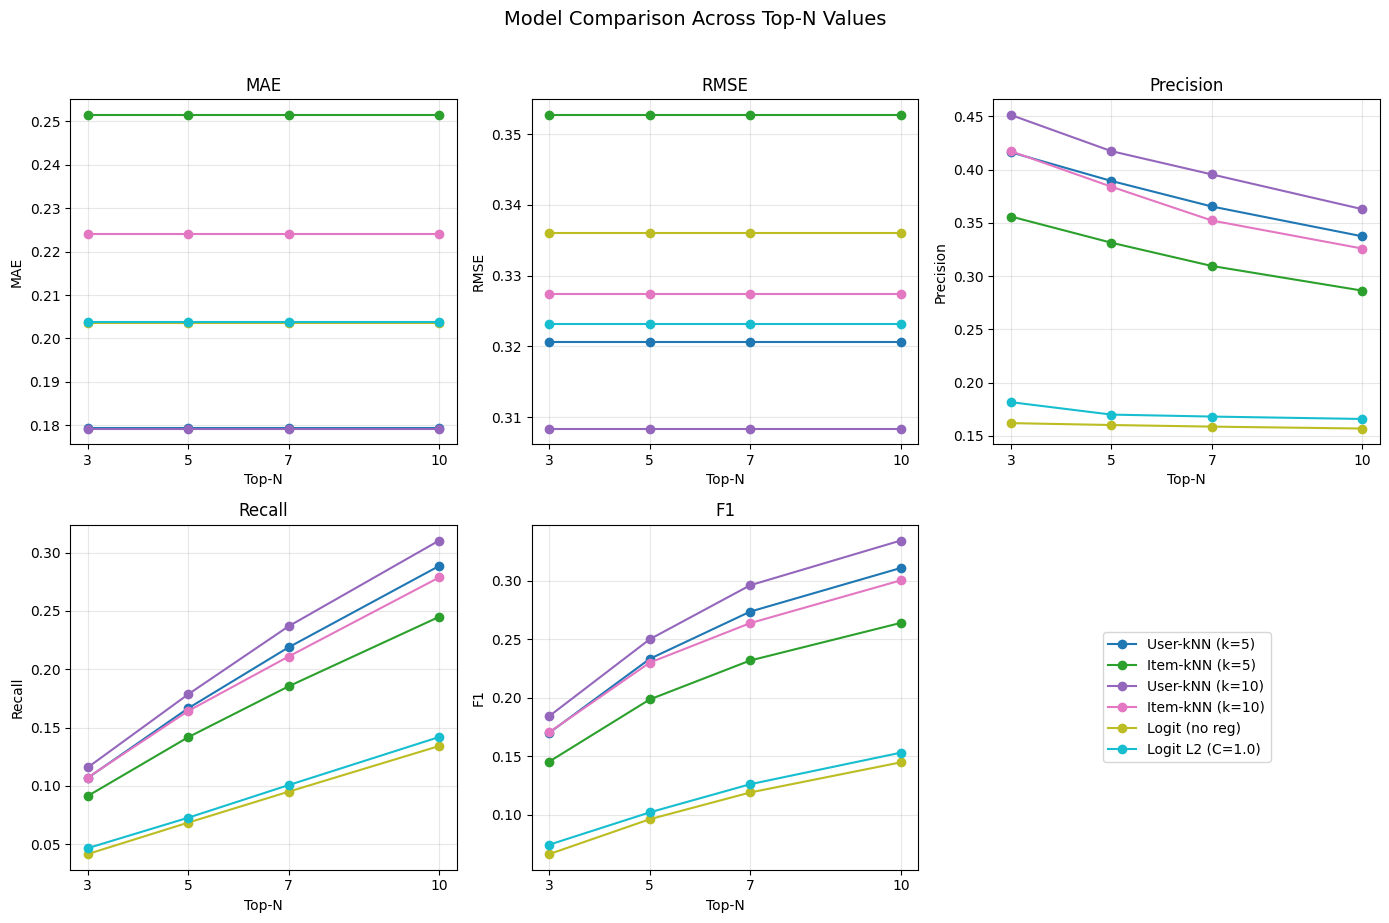

In [20]:
# Visualize metrics comparison
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
metrics = ['MAE', 'RMSE', 'Precision', 'Recall', 'F1']

models = results_df['Model'].unique()
colors = plt.cm.tab10(np.linspace(0, 1, len(models)))

for idx, metric in enumerate(metrics):
    ax = axes.flat[idx]
    for i, model in enumerate(models):
        data = results_df[results_df['Model'] == model]
        ax.plot(data['N'], data[metric], 'o-', color=colors[i], label=model)
    ax.set_xlabel('Top-N')
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.grid(True, alpha=0.3)
    ax.set_xticks(Ns)

axes.flat[-1].axis('off')
axes.flat[-1].legend(*axes.flat[0].get_legend_handles_labels(), 
                     loc='center', fontsize=10)

plt.suptitle('Model Comparison Across Top-N Values', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


## Summary

**Prediction Error (MAE/RMSE):**
- User-kNN achieves lowest MAE (~0.18) and RMSE (~0.31)
- Item-kNN slightly higher: MAE ~0.20-0.22, RMSE ~0.33
- Logit models worst: MAE ~0.25, RMSE ~0.35
- Regularization has minimal effect on logit performance

**Top-N Recommendation Quality:**
- **Best model: Item-kNN (k=10)** with highest Precision (~0.45 at N=3), Recall, and F1
- User-kNN performs well but below Item-kNN on precision/recall
- Logit models perform worst: Precision ~0.15-0.17, much lower than k-NN

**Key Findings (from data):**
1. k-NN outperforms logit on all metrics
2. Item-kNN has higher precision/recall than User-kNN
3. k=10 performs better than k=5 on precision/recall
4. Higher N increases recall but decreases precision


### Observations from Results

**What the data shows:**
- k-NN methods outperform logit on all metrics (MAE, RMSE, Precision, Recall, F1)
- Item-kNN achieves higher precision/recall than User-kNN
- Regularized and unregularized logit perform nearly identically
- Coefficients in simple logit are not extreme (no explosion observed)
